In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [10]:
df = pd.read_csv("UCI_Credit_Card.csv")
df = df.rename(columns={'default.payment.next.month': 'def_pay', 
                        'PAY_0': 'PAY_1'})

In [11]:
# Drop "ID" column.
data=df.drop(['ID'], axis=1)
print(f"There are {data.duplicated().sum()} duplicate rows in the data set.")
# Duplicate rows are removed.
df = df[~data.duplicated()]

There are 35 duplicate rows in the data set.


In [12]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,def_pay
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 29965 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         29965 non-null  int64  
 1   LIMIT_BAL  29965 non-null  float64
 2   SEX        29965 non-null  int64  
 3   EDUCATION  29965 non-null  int64  
 4   MARRIAGE   29965 non-null  int64  
 5   AGE        29965 non-null  int64  
 6   PAY_1      29965 non-null  int64  
 7   PAY_2      29965 non-null  int64  
 8   PAY_3      29965 non-null  int64  
 9   PAY_4      29965 non-null  int64  
 10  PAY_5      29965 non-null  int64  
 11  PAY_6      29965 non-null  int64  
 12  BILL_AMT1  29965 non-null  float64
 13  BILL_AMT2  29965 non-null  float64
 14  BILL_AMT3  29965 non-null  float64
 15  BILL_AMT4  29965 non-null  float64
 16  BILL_AMT5  29965 non-null  float64
 17  BILL_AMT6  29965 non-null  float64
 18  PAY_AMT1   29965 non-null  float64
 19  PAY_AMT2   29965 non-null  float64
 20  PAY_AMT3   

In [14]:
#  Marital status (1 = married; 2 = single; 3 = others).
df.MARRIAGE.value_counts()

MARRIAGE
2    15945
1    13643
3      323
0       54
Name: count, dtype: int64

In [15]:
df.loc[df.MARRIAGE == 0, 'MARRIAGE'] = 3
df.MARRIAGE.value_counts()

MARRIAGE
2    15945
1    13643
3      377
Name: count, dtype: int64

In [16]:
# Education (1 = graduate school; 2 = university; 3 = high school; 4 = others).
df.EDUCATION.value_counts() 

fil = (df.EDUCATION == 5) | (df.EDUCATION == 6) | (df.EDUCATION == 0)
df.loc[fil, 'EDUCATION'] = 4
df.EDUCATION.value_counts()

EDUCATION
2    14019
1    10563
3     4915
4      468
Name: count, dtype: int64

In [19]:
new_df = df.drop(columns=['BILL_AMT1', 'PAY_AMT6','def_pay','PAY_1','PAY_2'])
new_df = new_df.rename(columns={'PAY_3': 'July_Status', 
                        'PAY_4': 'June_Status',
                        'PAY_5': 'May_Status',
                        'PAY_6': 'April_Status',
                        'BILL_AMT2': 'August_Bill',
                        'BILL_AMT3': 'July_Bill',
                        'BILL_AMT4': 'June_Bill',
                        'BILL_AMT5': 'May_Bill',
                        'BILL_AMT6': 'April_Bill',
                        'PAY_AMT1': 'August_Pay',
                        'PAY_AMT2': 'July_Pay',
                        'PAY_AMT3': 'June_Pay',
                        'PAY_AMT4': 'May_Pay',
                        'PAY_AMT5': 'April_Pay'})

new_df.drop(columns=['ID'], inplace=True)

new_df['SEX'] = new_df.SEX.astype('category')
new_df['EDUCATION'] = new_df.EDUCATION.astype('category')
new_df['MARRIAGE'] = new_df.MARRIAGE.astype('category')
new_df['July_Status'] = new_df.July_Status.astype('category')
new_df['June_Status'] = new_df.June_Status.astype('category')
new_df['May_Status'] = new_df.May_Status.astype('category')
new_df['April_Status'] = new_df.April_Status.astype('category')

In [24]:
new_df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,July_Status,June_Status,May_Status,April_Status,August_Bill,July_Bill,June_Bill,May_Bill,April_Bill,August_Pay,July_Pay,June_Pay,May_Pay,April_Pay
0,20000.0,2,2,1,24,-1,-1,-2,-2,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0
1,120000.0,2,2,2,26,0,0,0,2,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0
2,90000.0,2,2,2,34,0,0,0,0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0
3,50000.0,2,2,1,37,0,0,0,0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0
4,50000.0,1,2,1,57,-1,0,0,0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0


In [25]:
zero_percentage = (new_df[['August_Bill', 'July_Bill', 'June_Bill', 'May_Bill', 'April_Bill', 'August_Pay', 'July_Pay', 'June_Pay', 'May_Pay', 'April_Pay']] == 0).mean() * 100
print('Zeros:')
print(zero_percentage)
print('********')
print('Negatives:')
neg_percentage = (new_df[['August_Bill', 'July_Bill', 'June_Bill', 'May_Bill', 'April_Bill']] < 0).mean() * 100
print(neg_percentage)

Zeros:
August_Bill     8.262973
July_Bill       9.477724
June_Bill      10.562323
May_Bill       11.600200
April_Bill     13.315535
August_Pay     17.413649
July_Pay       17.904222
June_Pay       19.813115
May_Pay        21.281495
April_Pay      22.265977
dtype: float64
********
Negatives:
August_Bill    2.232605
July_Bill      2.185884
June_Bill      2.252628
May_Bill       2.185884
April_Bill     2.296012
dtype: float64


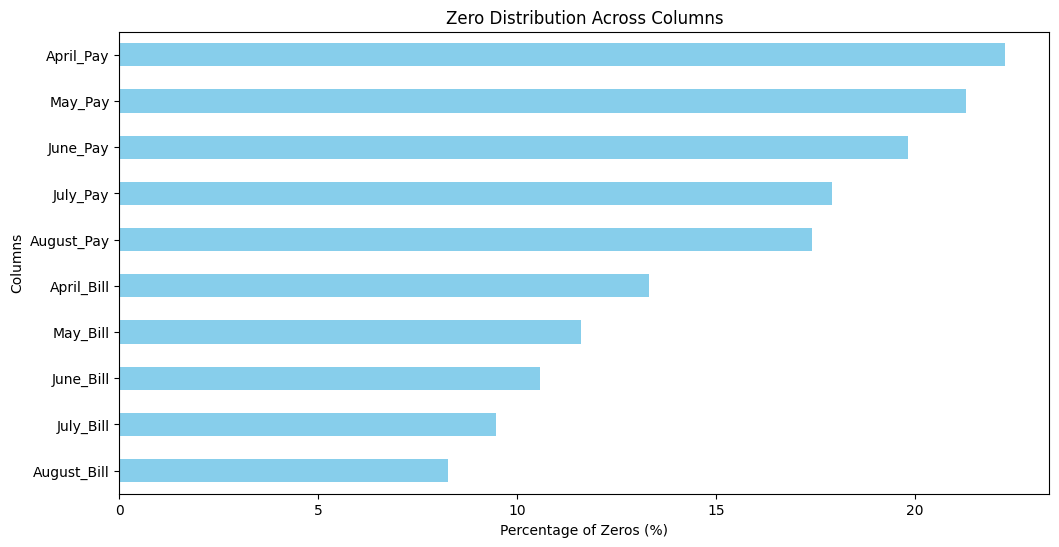

In [26]:
plt.figure(figsize=(12, 6))
zero_percentage.sort_values().plot(kind='barh', color='skyblue')
plt.xlabel("Percentage of Zeros (%)")
plt.ylabel("Columns")
plt.title("Zero Distribution Across Columns")
plt.show()

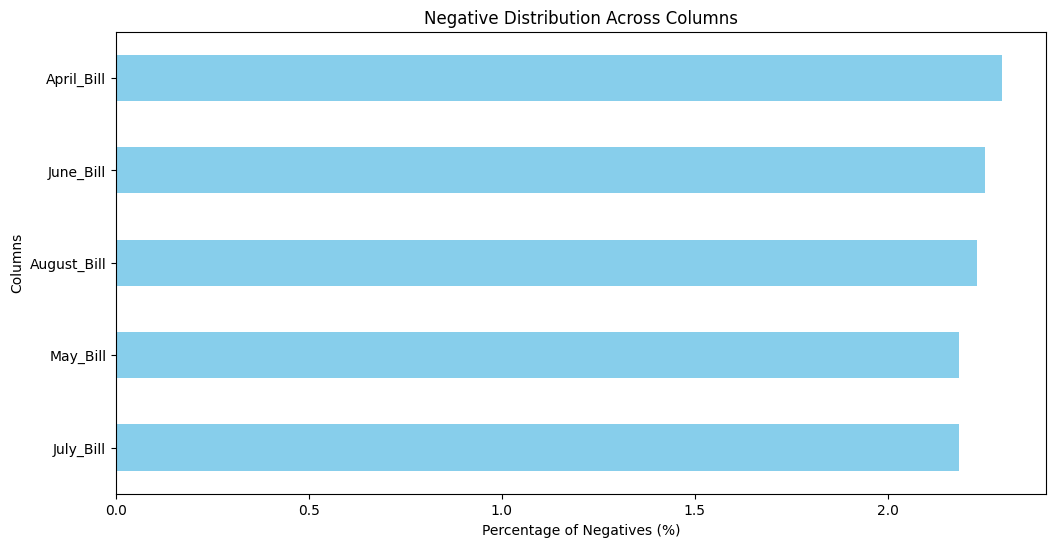

In [27]:
plt.figure(figsize=(12, 6))
neg_percentage.sort_values().plot(kind='barh', color='skyblue')
plt.xlabel("Percentage of Negatives (%)")
plt.ylabel("Columns")
plt.title("Negative Distribution Across Columns")
plt.show()

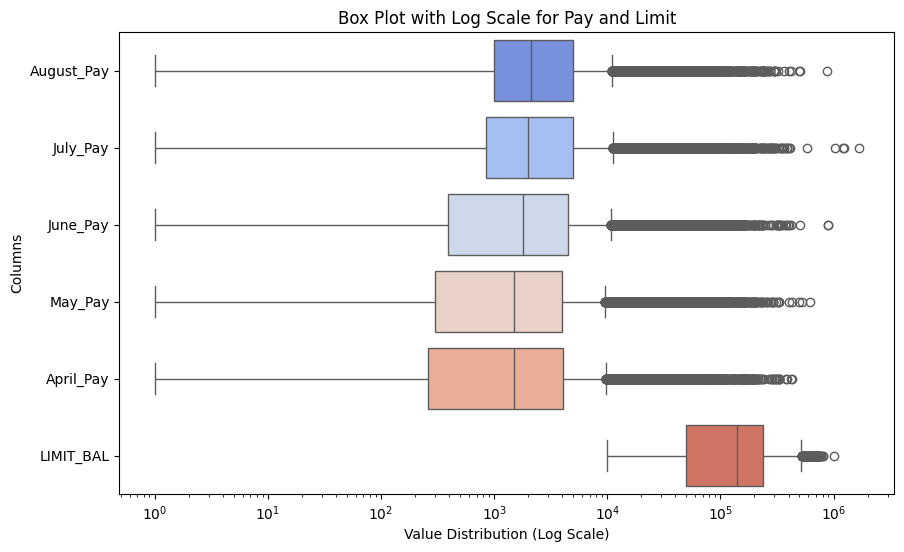

In [17]:
# Select numerical columns
num_cols = ['August_Pay', 'July_Pay', 'June_Pay', 'May_Pay', 'April_Pay','LIMIT_BAL' ]

filtered_df = new_df[num_cols].clip(lower=1)  # Replace negatives & zeros with 1

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=filtered_df, orient='h', palette="coolwarm")
ax.set_xscale('log')

plt.xlabel("Value Distribution (Log Scale)")
plt.ylabel("Columns")
plt.title("Box Plot with Log Scale for Pay and Limit")
plt.show()


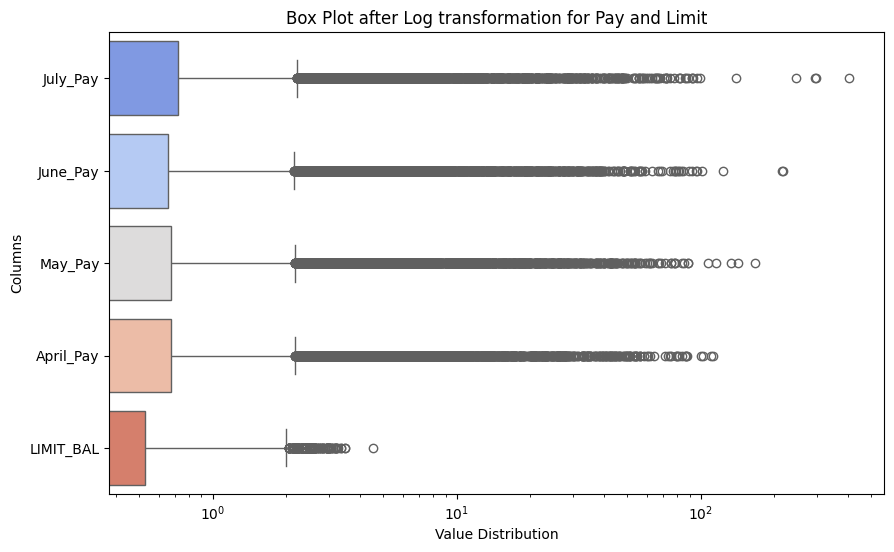

In [27]:
from sklearn.preprocessing import RobustScaler
transformer = RobustScaler()

rb_new_df = new_df.copy()

rb_new_df["LIMIT_BAL"] = transformer.fit_transform(new_df["LIMIT_BAL"].values.reshape(-1, 1)) # Robust scaling
rb_new_df["April_Pay"] = transformer.fit_transform(new_df["April_Pay"].values.reshape(-1, 1)) # Robust scaling
rb_new_df["May_Pay"] = transformer.fit_transform(new_df["May_Pay"].values.reshape(-1, 1)) #  Robust scaling
rb_new_df["June_Pay"] = transformer.fit_transform(new_df["June_Pay"].values.reshape(-1, 1)) # Robust scaling
rb_new_df["July_Pay"] = transformer.fit_transform(new_df["July_Pay"].values.reshape(-1, 1)) #  Robust scaling

# Select numerical columns
num_cols = ['July_Pay', 'June_Pay', 'May_Pay', 'April_Pay','LIMIT_BAL']

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=rb_new_df[num_cols], orient='h', palette="coolwarm")
ax.set_xscale('log')
plt.xlabel("Value Distribution")
plt.ylabel("Columns")
plt.title("Box Plot after Log transformation for Pay and Limit")
plt.show()


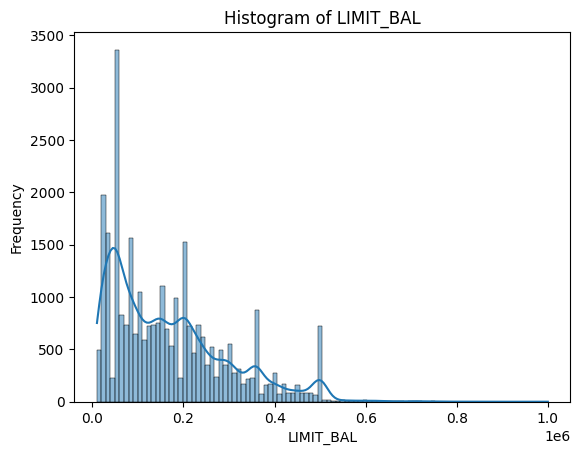

In [28]:
sns.histplot(new_df["LIMIT_BAL"], bins=100, kde=True)
plt.xlabel("LIMIT_BAL")
plt.ylabel("Frequency")
plt.title("Histogram of LIMIT_BAL")
plt.show()

In [34]:
rb_new_df = new_df.copy()
transformer = RobustScaler()
rb_new_df["LIMIT_BAL"] = transformer.fit_transform(new_df["LIMIT_BAL"].values.reshape(-1, 1)) # Robust scaling

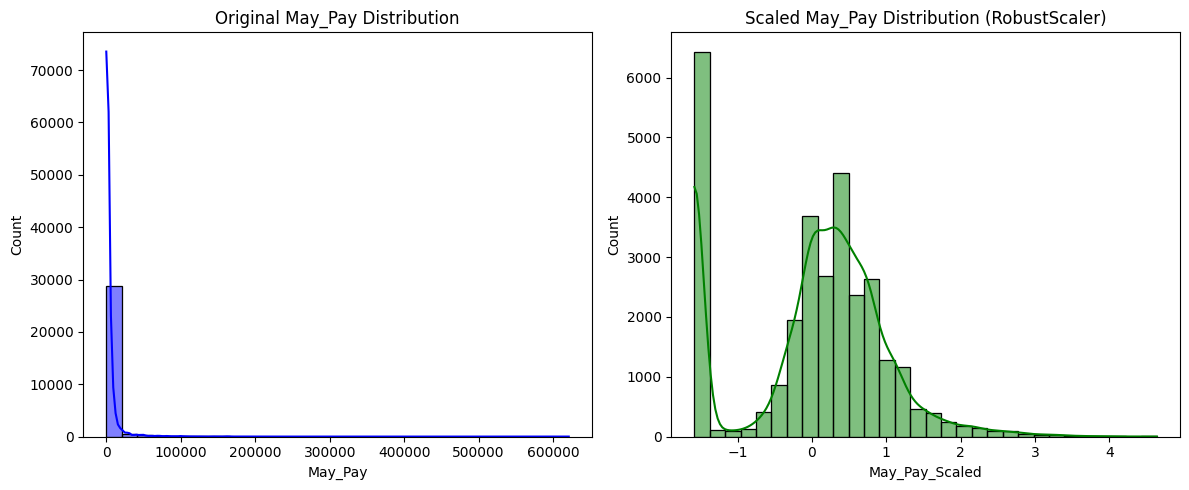

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PowerTransformer

plt.figure(figsize=(12, 5))

# Create DataFrame
temp_df = pd.DataFrame({"May_Pay": new_df["May_Pay"]})

# Initialize RobustScaler
power_transformer = PowerTransformer(method="yeo-johnson")

# Fit and transform LIMIT_BAL
temp_df["May_Pay_Scaled"] = power_transformer.fit_transform(temp_df[["May_Pay"]])

# Original Distribution
plt.subplot(1, 2, 1)
sns.histplot(temp_df["May_Pay"], bins=30, kde=True, color="blue")
plt.title("Original May_Pay Distribution")

# Scaled Distribution
plt.subplot(1, 2, 2)
sns.histplot(temp_df["May_Pay_Scaled"], bins=30, kde=True, color="green")
plt.title("Scaled May_Pay Distribution (RobustScaler)")

plt.tight_layout()
plt.show()

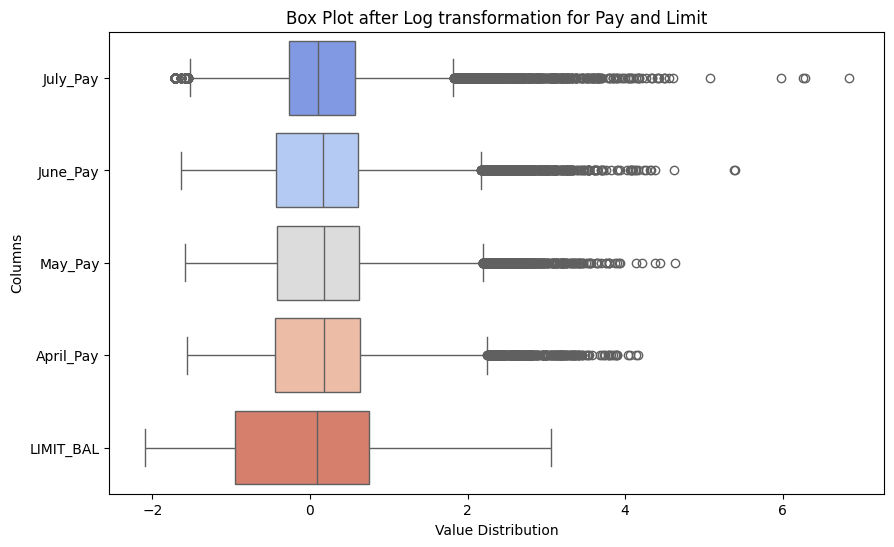

In [47]:
log_new_df = new_df.copy()

log_new_df["LIMIT_BAL"] = power_transformer.fit_transform(new_df[["LIMIT_BAL"]]) # Log transformation
log_new_df["April_Pay"] = power_transformer.fit_transform(new_df[["April_Pay"]]) # Log transformation
log_new_df["May_Pay"] = power_transformer.fit_transform(new_df[["May_Pay"]]) # Log transformation
log_new_df["June_Pay"] = power_transformer.fit_transform(new_df[["June_Pay"]]) # Log transformation
log_new_df["July_Pay"] = power_transformer.fit_transform(new_df[["July_Pay"]]) # Log transformation

# Select numerical columns
num_cols = ['July_Pay', 'June_Pay', 'May_Pay', 'April_Pay','LIMIT_BAL']

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=log_new_df[num_cols], orient='h', palette="coolwarm")
plt.xlabel("Value Distribution")
plt.ylabel("Columns")
plt.title("Box Plot after Log transformation for Pay and Limit")
plt.show()

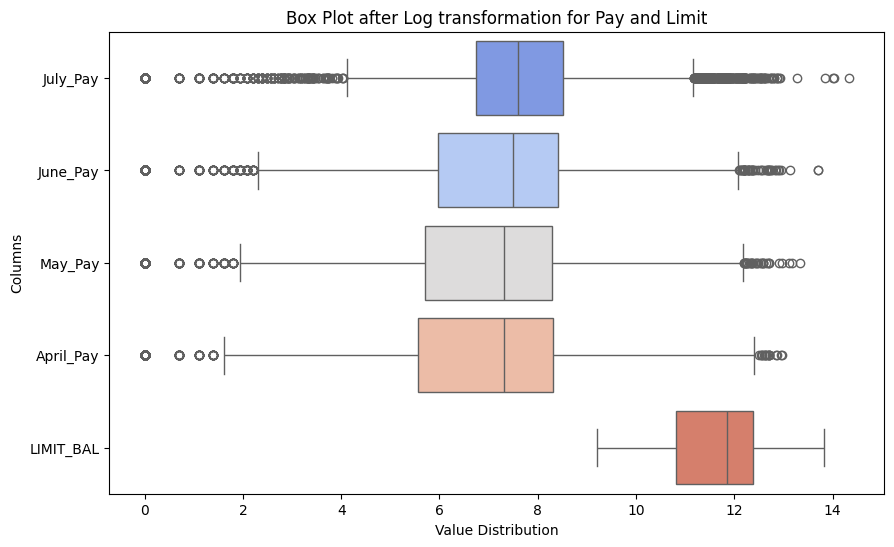

In [15]:
log_new_df = new_df.copy()

log_new_df["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation
log_new_df["April_Pay"] = np.log1p(new_df["April_Pay"]) # Log transformation
log_new_df["May_Pay"] = np.log1p(new_df["May_Pay"]) # Log transformation
log_new_df["June_Pay"] = np.log1p(new_df["June_Pay"]) # Log transformation
log_new_df["July_Pay"] = np.log1p(new_df["July_Pay"]) # Log transformation

# Select numerical columns
num_cols = ['July_Pay', 'June_Pay', 'May_Pay', 'April_Pay','LIMIT_BAL']

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=log_new_df[num_cols], orient='h', palette="coolwarm")

plt.xlabel("Value Distribution")
plt.ylabel("Columns")
plt.title("Box Plot after Log transformation for Pay and Limit")
plt.show()


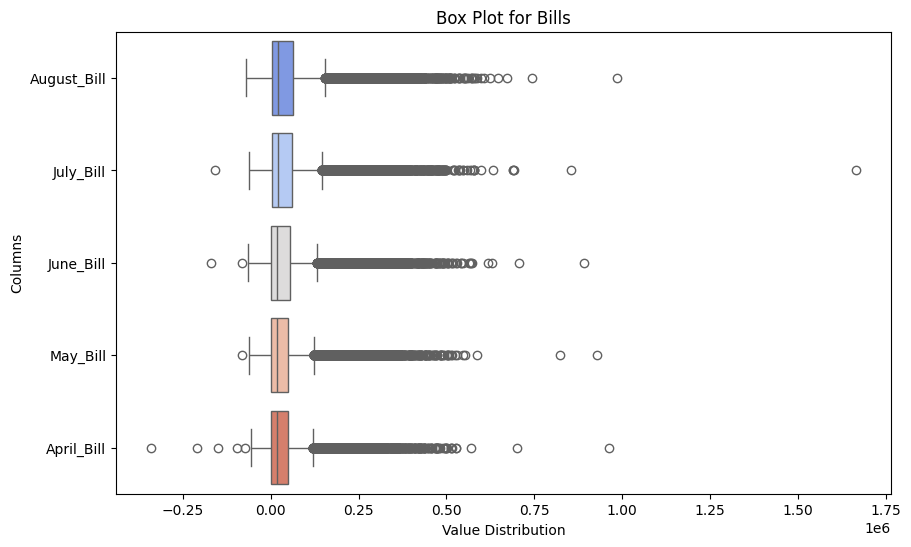

In [16]:
# Select numerical columns
num_cols = ['August_Bill', 'July_Bill', 'June_Bill', 'May_Bill', 'April_Bill']

plt.figure(figsize=(10, 6))
ax = sns.boxplot(data=new_df[num_cols], orient='h', palette="coolwarm")

# Set x-axis to log scale
plt.xlabel("Value Distribution")
plt.ylabel("Columns")
plt.title("Box Plot for Bills")
plt.show()


# Base Model Linear Regression

In [17]:
X_train, X_test, y_train, y_test = train_test_split(new_df.drop(columns=['August_Pay']), new_df['August_Pay'], test_size=0.2, random_state=42)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 16775.747652828817


# Residuals vs Limits

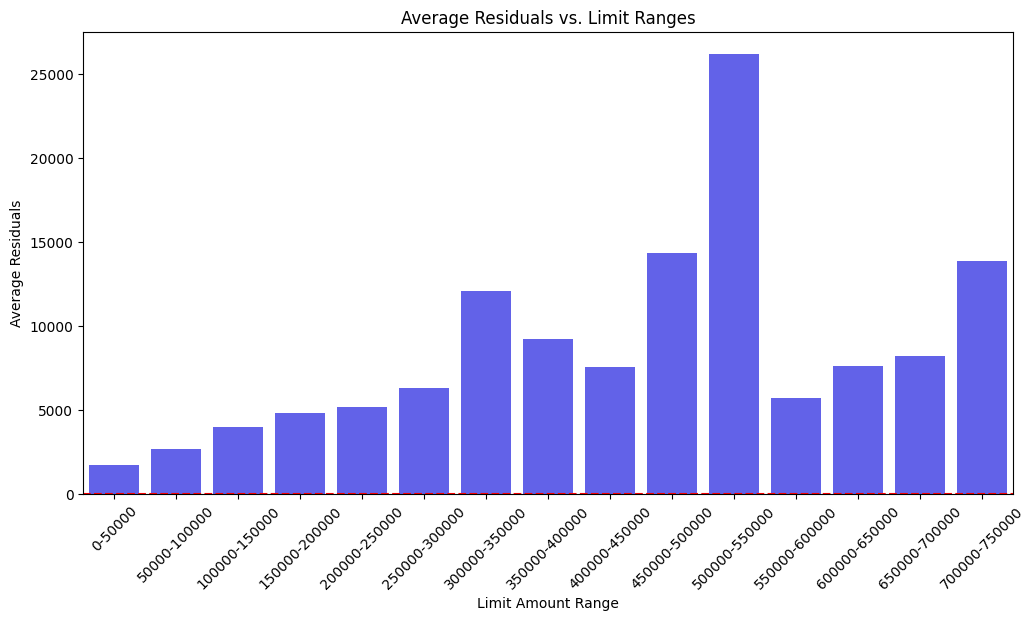

In [18]:
y_pred = linear_model.predict(X_test)

residuals = y_test - y_pred

# Create DataFrame
temp_df = pd.DataFrame({"Limit": X_test["LIMIT_BAL"], "Residuals": abs(residuals)})

# Define bin edges (adjust as needed)
bins = np.arange(0, temp_df["Limit"].max() + 50000, 50000)  # Bins every 5000 units
labels = [f"{int(bins[i])}-{int(bins[i+1])}" for i in range(len(bins)-1)]

# Assign bins
temp_df["Bill_Range"] = pd.cut(temp_df["Limit"], bins=bins, labels=labels, include_lowest=True)

# Compute average residuals for each bin
mean_residuals = temp_df.groupby("Bill_Range")["Residuals"].mean().reset_index()

# Plot the average residuals for each bill range
plt.figure(figsize=(12, 6))
sns.barplot(x="Bill_Range", y="Residuals", data=mean_residuals, color="blue", alpha=0.7)
plt.axhline(0, color='red', linestyle='dashed')  # Reference line at y=0
plt.xlabel("Limit Amount Range")
plt.ylabel("Average Residuals")
plt.title("Average Residuals vs. Limit Ranges")
plt.xticks(rotation=45)  # Rotate labels for readability
plt.show()


# Histograms and Log Normalizations

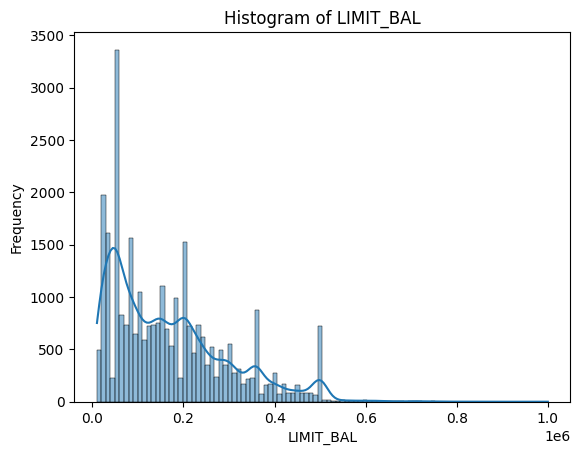

In [19]:
sns.histplot(new_df["LIMIT_BAL"], bins=100, kde=True)
plt.xlabel("LIMIT_BAL")
plt.ylabel("Frequency")
plt.title("Histogram of LIMIT_BAL")
plt.show()

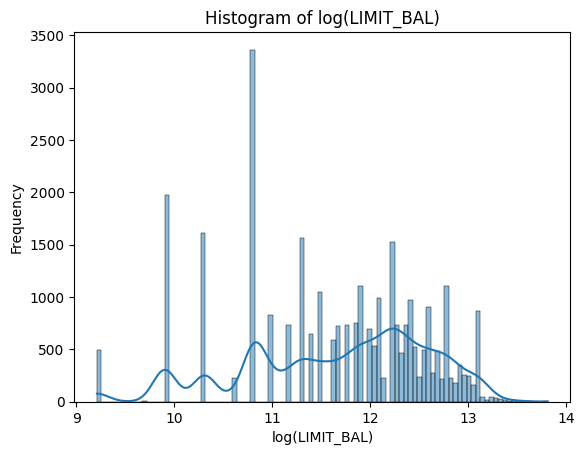

In [20]:
temp = np.log1p(new_df["LIMIT_BAL"]) # Log transformation
sns.histplot(temp, bins=100, kde=True)
plt.xlabel("log(LIMIT_BAL)")
plt.ylabel("Frequency")
plt.title("Histogram of log(LIMIT_BAL)")
plt.show()

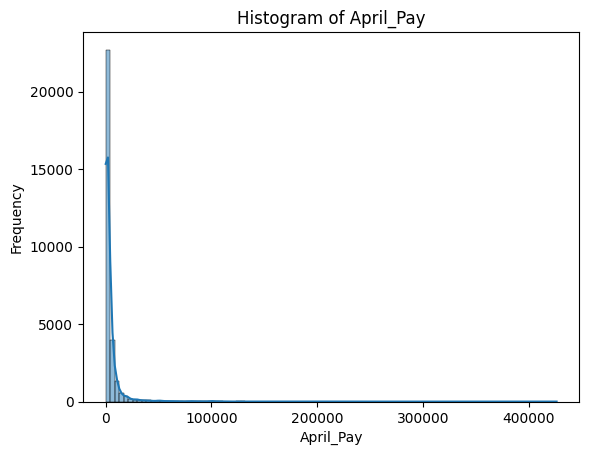

In [21]:
sns.histplot(new_df["April_Pay"], bins=100, kde=True)
plt.xlabel("April_Pay")
plt.ylabel("Frequency")
plt.title("Histogram of April_Pay")
plt.show()

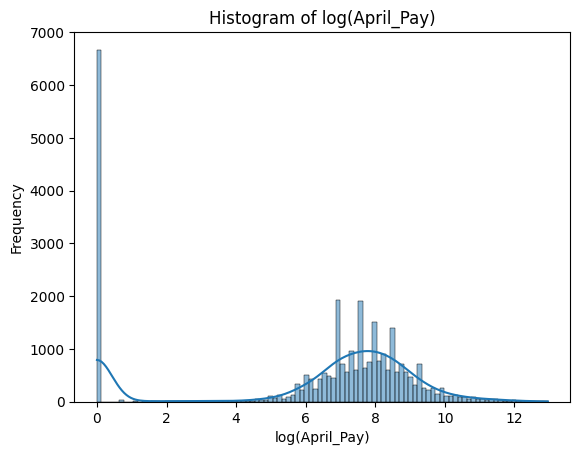

In [22]:
temp = np.log1p(new_df["April_Pay"]) # Log transformation

sns.histplot(temp, bins=100, kde=True)
plt.xlabel("log(April_Pay)")
plt.ylabel("Frequency")
plt.title("Histogram of log(April_Pay)")
plt.show()

# Base RMSE: 16775.747652828817

# log Transformation of Payments and Limit

In [23]:
log_new_df = new_df.copy()

log_new_df["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation

log_new_df["April_Pay"] = np.log1p(new_df["April_Pay"]) # Log transformation
log_new_df["May_Pay"] = np.log1p(new_df["May_Pay"]) # Log transformation
log_new_df["June_Pay"] = np.log1p(new_df["June_Pay"]) # Log transformation
log_new_df["July_Pay"] = np.log1p(new_df["July_Pay"]) # Log transformation

X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
root_mean_squared_error(y_test, linear_model.predict(X_test))
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")


RMSE: 19700.771649143666


# log Transformation of Limit

In [24]:
log_new_df = new_df.copy()

log_new_df["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation

X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
root_mean_squared_error(y_test, linear_model.predict(X_test))
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 16752.57745188237


# Adding features for averaging and dropping

In [25]:
log_new_df = new_df.copy()
log_new_df["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].mean(axis=1)
log_new_df.drop(columns=['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill'], inplace=True)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].mean(axis=1)
log_new_df.drop(columns=['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay'], inplace=True)

X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")


RMSE: 17224.077922842516


# Adding features for averaging without dropping

In [26]:
log_new_df = new_df.copy()
log_new_df["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].mean(axis=1)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].mean(axis=1)

X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 16751.087593309618


# Adding features for averaging (only non zeros) and without dropping

In [27]:
log_new_df = new_df.copy()
log_new_df["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)

X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 16744.81184199204


# Adding features for age bins

In [28]:
# Create a new column for bins
log_new_df = new_df.copy()
log_new_df["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)

# Define bins for AGE
bins = [20, 29, 39, 49, 59, 69, 81]
bins_names = [1, 2, 3, 4, 5, 6]
log_new_df['AgeBin'] = 0
log_new_df['AgeBin'] = pd.cut(new_df['AGE'], bins, labels=bins_names).astype('category')

X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")


RMSE: 16744.10565450551


# Adding features for limit bins

In [29]:
# Create a new column for bins
log_new_df = new_df.copy()
log_new_df["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)

# Define bins for AGE
bins = [20, 29, 39, 49, 59, 69, 81]
bins_names = [1, 2, 3, 4, 5, 6]
log_new_df['AgeBin'] = 0
log_new_df['AgeBin'] = pd.cut(new_df['AGE'], bins, labels=bins_names).astype('category')

# Define bins for LIMIT_BAL
bins = [0, 100000, 200000, 300000, 400000, 500000, new_df["LIMIT_BAL"].max()]
labels = ["1", "2", "3", "4", "5", "6"]

# Create a new column for bins
log_new_df["LIMIT_BAL_bin"] = pd.cut(new_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True).astype('category')

X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 16759.42559029586


# Adding Extra Features

In [30]:
# Create a new column for bins
log_new_df = new_df.copy()
log_new_df ["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["MAX_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].max(axis=1) 
log_new_df ["MAX_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].max(axis=1)
log_new_df ["MIN_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].min(axis=1)
log_new_df ["MIN_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].min(axis=1)
log_new_df ["LIMIT_PAY_RATIO"] =  log_new_df ["AVG_PAY_AMT"] / new_df["LIMIT_BAL"]
log_new_df ["LIMIT_BILL_RATIO"] =  log_new_df ["AVG_BILL_AMT"] / new_df["LIMIT_BAL"]
log_new_df ["PAY_SUM"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].sum(axis=1)
log_new_df ["BILL_SUM"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].sum(axis=1)
log_new_df ["CUM_PAY_JUN_JUL"] = new_df [['June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL"] = new_df [['June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_PAY_JUN_JUL_MAY"] = new_df [['May_Pay', 'June_Pay', 'July_Pay']].cumsum(axis=1).iloc[:, -1]
log_new_df ["CUM_BILL_JUN_JUL_MAY"] = new_df [['May_Bill', 'June_Bill', 'July_Bill']].cumsum(axis=1).iloc[:, -1]

# Define bins for AGE
bins = [20, 29, 39, 49, 59, 69, 81]
bins_names = [1, 2, 3, 4, 5, 6]
log_new_df['AgeBin'] = 0
log_new_df['AgeBin'] = pd.cut(new_df['AGE'], bins, labels=bins_names).astype('category')

# Define bins for LIMIT_BAL
bins = [0, 100000, 200000, 300000, 400000, 500000, new_df["LIMIT_BAL"].max()]
labels = ["1", "2", "3", "4", "5", "6"]
log_new_df["LIMIT_BAL_bin"] = pd.cut(new_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True).astype('category')

X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 15645.312565322489


# Oversampling (Base RMSE: 16759.42559029586)

In [31]:
# Create a new column for bins
log_new_df = new_df.copy()
log_new_df["LIMIT_BAL"] = np.log1p(new_df["LIMIT_BAL"]) # Log transformation
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)

# Define bins for AGE
bins = [20, 29, 39, 49, 59, 69, 81]
bins_names = [1, 2, 3, 4, 5, 6]
log_new_df['AgeBin'] = 0
log_new_df['AgeBin'] = pd.cut(new_df['AGE'], bins, labels=bins_names).astype('category')

# Define bins for LIMIT_BAL
bins = [0, 100000, 200000, 300000, 400000, 500000, new_df["LIMIT_BAL"].max()]
labels = ["0-100k", "100k-200k", "200k-300k", "300k-400k", "400k-500k", "500k+"]

# Create a new column for bins
log_new_df["LIMIT_BAL_bin"] = pd.cut(new_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True)

X_train, X_test, y_train, y_test = train_test_split(log_new_df.drop(columns=['August_Pay']), log_new_df['August_Pay'], test_size=0.2, random_state=42)

# Store models and their respective bins
models = {}

for bin_label in X_train["LIMIT_BAL_bin"].unique():

    X_temp = X_train[X_train["LIMIT_BAL_bin"] == bin_label].drop(columns=["LIMIT_BAL_bin"]) 
    Y_temp = y_train[X_train["LIMIT_BAL_bin"] == bin_label]

    linear_model = LinearRegression()
    linear_model.fit(X_temp, Y_temp)
    models[bin_label] = linear_model

rmse_list = {}
for bin_label in X_test["LIMIT_BAL_bin"].unique():
    X_temp = X_test[X_test["LIMIT_BAL_bin"] == bin_label].drop(columns=["LIMIT_BAL_bin"]) 
    Y_temp = y_test[X_test["LIMIT_BAL_bin"] == bin_label]

    rmse_list[bin_label] = root_mean_squared_error(Y_temp, models[bin_label].predict(X_temp))
    print(f"RMSE for {bin_label}: {root_mean_squared_error(Y_temp, models[bin_label].predict(X_temp))}")


log_new_df["LIMIT_BAL_bin"].value_counts()


RMSE for 0-100k: 4733.387504989308
RMSE for 100k-200k: 13814.237749228592
RMSE for 400k-500k: 29103.170785968727
RMSE for 200k-300k: 13458.810951530713
RMSE for 300k-400k: 32283.472148180987
RMSE for 500k+: 36452.18542940437


LIMIT_BAL_bin
0-100k       12490
100k-200k     7867
200k-300k     5053
300k-400k     2752
400k-500k     1597
500k+          206
Name: count, dtype: int64

In [32]:
from imblearn.over_sampling import SMOTE


# Create a new column for bins
log_new_df = new_df.copy()
log_new_df ["AVG_BILL_AMT"] = new_df [['April_Bill', 'May_Bill', 'June_Bill', 'July_Bill']].replace(0, np.nan).mean(axis=1).fillna(0)
log_new_df ["AVG_PAY_AMT"] = new_df [['April_Pay', 'May_Pay', 'June_Pay', 'July_Pay']].replace(0, np.nan).mean(axis=1).fillna(0)


# Define bins for AGE
bins = [20, 29, 39, 49, 59, 69, 81]
bins_names = [1, 2, 3, 4, 5, 6]
log_new_df['AgeBin'] = 0
log_new_df['AgeBin'] = pd.cut(new_df['AGE'], bins, labels=bins_names).astype('category')

# Define bins for LIMIT_BAL
bins = [0, 100000, 200000, 300000, 400000, 500000, new_df["LIMIT_BAL"].max()]
labels = ["0-100k", "100k-200k", "200k-300k", "300k-400k", "400k-500k", "500k+"]

# Create a new column for bins
log_new_df["LIMIT_BAL_bin"] = pd.cut(new_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True)

print("Before SMOTE:")
print(log_new_df.LIMIT_BAL_bin.value_counts())

##########################################  SMOTE ##########################################

X_train, X_test, _, y_test = train_test_split(log_new_df, log_new_df['August_Pay'], test_size=0.2, random_state=42)

X_test.drop(columns=['August_Pay'], inplace=True)
X_test["LIMIT_BAL"] = np.log1p(X_test["LIMIT_BAL"]) # Log transformation

# Define numerical and categorical features
numerical_features = ["LIMIT_BAL", "AVG_BILL_AMT", "AVG_PAY_AMT", "August_Bill", "July_Bill", "June_Bill", "May_Bill", "April_Bill", "August_Pay", "July_Pay", "June_Pay", "May_Pay", "April_Pay"]
categorical_features = ["SEX", "EDUCATION", "MARRIAGE", "July_Status", "June_Status", "May_Status", "April_Status", "AGE"]
target_column = "LIMIT_BAL_bin"

# Separate numerical and categorical data
X_numerical = X_train[numerical_features]
X_categorical = X_train[categorical_features]  # Store categorical data separately
y = X_train[target_column]

# Apply SMOTE only on numerical features
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, _ = smote.fit_resample(X_numerical, y)

# Convert to DataFrame
X_resampled_df = pd.DataFrame(X_resampled, columns=numerical_features)

# **Re-add categorical variables by sampling from original data**
X_categorical_resampled = X_categorical.sample(n=len(X_resampled_df), replace=True, random_state=42).reset_index(drop=True)

# Combine numerical, categorical, and target columns
final_df = pd.concat([X_resampled_df, X_categorical_resampled], axis=1)

# Define bins for AGE
bins = [20, 29, 39, 49, 59, 69, 81]
labels = [1, 2, 3, 4, 5, 6]
final_df['AgeBin'] = 0
final_df['AgeBin'] = pd.cut(final_df['AGE'], bins, labels=labels).astype('category')

# Define bins for LIMIT_BAL
bins = [0, 100000, 200000, 300000, 400000, 500000, new_df["LIMIT_BAL"].max()]
labels = ["0-100k", "100k-200k", "200k-300k", "300k-400k", "400k-500k", "500k+"]
final_df["LIMIT_BAL_bin"] = pd.cut(final_df["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True)

# Check new distribution
print("\nAfter SMOTE:")
print(final_df[target_column].value_counts())

final_df["LIMIT_BAL"] = np.log1p(final_df["LIMIT_BAL"]) # Log transformation


Before SMOTE:
LIMIT_BAL_bin
0-100k       12490
100k-200k     7867
200k-300k     5053
300k-400k     2752
400k-500k     1597
500k+          206
Name: count, dtype: int64

After SMOTE:
LIMIT_BAL_bin
0-100k       10008
100k-200k    10008
200k-300k    10008
300k-400k    10008
400k-500k    10008
500k+        10008
Name: count, dtype: int64


In [33]:
y_train = final_df['August_Pay']
X_train = final_df
X_train.drop(columns=['August_Pay'], inplace=True)

X_train = X_train.reindex(sorted(X_train.columns), axis=1)
X_test = X_test.reindex(sorted(X_test.columns), axis=1)


# Store models and their respective bins
models = {}

for bin_label in X_train["LIMIT_BAL_bin"].unique():

    X_temp = X_train[X_train["LIMIT_BAL_bin"] == bin_label].drop(columns=["LIMIT_BAL_bin"]) 
    Y_temp = y_train[X_train["LIMIT_BAL_bin"] == bin_label]

    linear_model = LinearRegression()
    linear_model.fit(X_temp, Y_temp)
    models[bin_label] = linear_model

rmse_list = {}
for bin_label in X_test["LIMIT_BAL_bin"].unique():
    X_temp = X_test[X_test["LIMIT_BAL_bin"] == bin_label].drop(columns=["LIMIT_BAL_bin"]) 
    Y_temp = y_test[X_test["LIMIT_BAL_bin"] == bin_label]

    rmse_list[bin_label] = root_mean_squared_error(Y_temp, models[bin_label].predict(X_temp))
    print(f"RMSE for {bin_label}: {root_mean_squared_error(Y_temp, models[bin_label].predict(X_temp))}")


X_train["LIMIT_BAL_bin"].value_counts()

RMSE for 0-100k: 4731.518473219413
RMSE for 100k-200k: 13820.52001374805
RMSE for 400k-500k: 29075.01483905905
RMSE for 200k-300k: 13415.814927599575
RMSE for 300k-400k: 31949.60744414329
RMSE for 500k+: 39246.940521586774


LIMIT_BAL_bin
0-100k       10008
100k-200k    10008
200k-300k    10008
300k-400k    10008
400k-500k    10008
500k+        10008
Name: count, dtype: int64

In [34]:
X_train["LIMIT_BAL"] = np.expm1(X_train["LIMIT_BAL"])  
X_test["LIMIT_BAL"] = np.expm1(X_test["LIMIT_BAL"]) 

In [35]:
# Define bins for LIMIT_BAL
bins = [0, 100000, 200000, 300000, 400000, 500000, new_df["LIMIT_BAL"].max()]
labels = ["1", "2", "3", "4", "5", "6"]
X_train["LIMIT_BAL_bin"] = pd.cut(X_train["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True).astype('category')
X_test["LIMIT_BAL_bin"] = pd.cut(X_test["LIMIT_BAL"], bins=bins, labels=labels, include_lowest=True).astype('category')

X_train["LIMIT_BAL"] = np.log1p(X_train["LIMIT_BAL"])  
X_test["LIMIT_BAL"] = np.log1p(X_test["LIMIT_BAL"]) 

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
print(f"RMSE: {root_mean_squared_error(y_test, linear_model.predict(X_test))}")

RMSE: 16365.905325065924
